# UAE E-commerce Fraud & Sales Analytics — Deep Data Science Notebook

**Purpose:** Comprehensive analysis of the supplied 100K UAE e-commerce transaction dataset from a Data Scientist perspective.

This notebook includes:
1. Python data analysis, profiling and data-quality audit.
2. Sales / transaction-value reporting and visualizations.
3. Fraud segmentation, time trends, statistical tests and correlations.
4. Existing fraud-rule performance and overlap.
5. Supervised machine learning with chronological validation.
6. Unsupervised anomaly detection and clustering.
7. Optional CPU-friendly PyTorch deep learning.
8. NLP applicability assessment and optional text model.
9. Cost-based decision analysis, SQLite cross-checks, fairness and drift.
10. Executive report and reproducibility artifacts.

**Important:** The project dataset has previously been identified as synthetic (`synthetic:ecom-fraud-uae-v1`). This is a proof of concept, not evidence of real-world or production performance. `amount_aed` is transaction value / GTV, not accounting revenue or profit.

## 0. Environment and configuration

In [1]:
import os, sys, json, sqlite3, warnings, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency, mannwhitneyu, norm

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, fbeta_score, confusion_matrix, classification_report, brier_score_loss,
    precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns",100)
pd.set_option("display.width",180)
RANDOM_STATE=42
TARGET="is_fraud"
DATA_PATH="uae_ecom_fraud_100k.csv"  # change to your actual path
if not Path(DATA_PATH).exists() and Path("uae_ecom_fraud_100k.parquet").exists():
    DATA_PATH="uae_ecom_fraud_100k.parquet"
REPORT_DIR=Path("reports"); REPORT_DIR.mkdir(exist_ok=True)
MODEL_DIR=Path("models"); MODEL_DIR.mkdir(exist_ok=True)

EXPECTED_COLUMNS=[
"transaction_id","user_id","timestamp_utc","amount_aed","currency","payment_method","device_type",
"browser","merchant_category","items_count","avg_item_price","shipping_city","billing_city",
"shipping_billing_match","ip_address","ip_risk_score","card_present","bin_country","card_age_days",
"card_country_match","email_domain","user_prev_chargebacks","user_is_high_risk","user_account_age_days",
"transactions_last_24h","transactions_last_1h","local_hour","odd_hour","is_fraud","fraud_flag_ip",
"fraud_flag_mismatch","fraud_flag_velocity","fraud_flag_new_account","fraud_flag_prev_cb",
"fraud_flag_odd_hour","data_source"]
FLAG_COLS=[c for c in EXPECTED_COLUMNS if c.startswith("fraud_flag_")]
print("Python:",sys.version.split()[0],"Platform:",platform.platform())
print("Dataset path:",DATA_PATH)

Python: 3.13.14 Platform: Windows-10-10.0.19045-SP0
Dataset path: uae_ecom_fraud_100k.csv


## 1. Load and profile the dataset

In [2]:
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}. Place CSV/parquet beside notebook or edit DATA_PATH.")
raw=pd.read_parquet(DATA_PATH) if DATA_PATH.lower().endswith(".parquet") else pd.read_csv(DATA_PATH)
print("Shape:",raw.shape,"Memory MB:",round(raw.memory_usage(deep=True).sum()/1024**2,2))
display(raw.head())
display(raw.dtypes.astype(str).to_frame("dtype"))
display(raw.isna().sum().sort_values(ascending=False).to_frame("null_count"))
missing=sorted(set(EXPECTED_COLUMNS)-set(raw.columns))
extra=sorted(set(raw.columns)-set(EXPECTED_COLUMNS))
print("Missing expected columns:",missing)
print("Extra columns:",extra)
if TARGET not in raw: raise ValueError("is_fraud target column is required.")

Shape: (100000, 36) Memory MB: 38.51


,transaction_id,user_id,timestamp_utc,amount_aed,currency,payment_method,device_type,browser,merchant_category,items_count,avg_item_price,shipping_city,billing_city,shipping_billing_match,ip_address,ip_risk_score,card_present,bin_country,card_age_days,card_country_match,email_domain,user_prev_chargebacks,user_is_high_risk,user_account_age_days,transactions_last_24h,transactions_last_1h,local_hour,odd_hour,is_fraud,fraud_flag_ip,fraud_flag_mismatch,fraud_flag_velocity,fraud_flag_new_account,fraud_flag_prev_cb,fraud_flag_odd_hour,data_source
0,500086758,1000466,2024-01-01T00:02:03Z,71.47,AED,card,desktop,Chrome,Pharmacy,3,23.82,Dubai,Dubai,1,144.108.182.242,35.3,0,AE,85,1,gmail.com,0,0,365,0,0,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
1,500060464,1002828,2024-01-01T00:03:11Z,70.25,AED,card,mobile,Chrome,Groceries,1,70.25,Abu Dhabi,Abu Dhabi,1,104.37.234.72,30.2,0,SA,123,0,outlook.com,0,0,-192,0,0,4,1,0,0,0,0,1,0,1,synthetic:ecom-fraud-uae-v1
2,500039909,1010349,2024-01-01T00:04:10Z,116.25,AED,bank_transfer,desktop,Chrome,Beauty,2,58.12,Cairo,Cairo,1,89.169.143.66,32.7,0,PK,542,0,gmail.com,0,0,1744,0,0,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
3,500074412,1015360,2024-01-01T00:05:14Z,99.41,AED,apple_pay,mobile,Safari,Toys,2,49.70,Mumbai,Mumbai,1,37.54.200.109,30.3,0,EG,981,0,outlook.com,0,0,102,0,0,4,1,0,0,0,0,0,0,1,synthetic:ecom-fraud-uae-v1
4,500038110,1022253,2024-01-01T00:11:03Z,529.40,AED,card,desktop,Safari,Travel,2,264.70,Dubai,Dubai,1,18.172.52.222,18.5,0,AE,515,1,gmail.com,1,1,-59,0,0,4,1,0,0,0,0,1,1,1,synthetic:ecom-fraud-uae-v1


,dtype
transaction_id,int64
user_id,int64
timestamp_utc,str
amount_aed,float64
currency,str
payment_method,str
device_type,str
browser,str
merchant_category,str
items_count,int64


,null_count
transaction_id,0
user_id,0
timestamp_utc,0
amount_aed,0
currency,0
payment_method,0
device_type,0
browser,0
merchant_category,0
items_count,0


Missing expected columns: []
Extra columns: []


## 2. Data-quality audit and cleaning

In [3]:
df=raw.copy()
df["timestamp_utc"]=pd.to_datetime(df["timestamp_utc"],errors="coerce",utc=True)
df[TARGET]=pd.to_numeric(df[TARGET],errors="coerce")
audit=[]
def log_issue(issue,mask,decision,reason):
    mask=pd.Series(mask,index=df.index).fillna(False).astype(bool)
    n=int(mask.sum())
    if n: audit.append({"issue":issue,"rows":n,"pct":100*n/len(df),"decision":decision,"reason":reason})
log_issue("Invalid timestamp",df["timestamp_utc"].isna(),"Quarantine","Cannot chronologically order missing/invalid timestamps.")
log_issue("Invalid target",~df[TARGET].isin([0,1]),"Quarantine","Target must be binary.")
if "transaction_id" in df:
    log_issue("Duplicate transaction_id",df["transaction_id"].duplicated(keep="first"),"Quarantine later duplicates","Assumes one canonical row per transaction.")
num_cols=["amount_aed","items_count","avg_item_price","ip_risk_score","card_age_days","user_prev_chargebacks",
          "user_account_age_days","transactions_last_24h","transactions_last_1h","local_hour"]
for c in num_cols:
    if c in df: df[c]=pd.to_numeric(df[c],errors="coerce")
if "user_account_age_days" in df:
    bad=df["user_account_age_days"]<0
    log_issue("Negative account age",bad,"Flag and set missing","Keep transaction; invalid age needs source-generation investigation.")
    df["account_age_invalid_flag"]=bad.astype("int8")
    df.loc[bad,"user_account_age_days"]=np.nan
for c in ["amount_aed","items_count","avg_item_price","ip_risk_score","card_age_days",
          "user_prev_chargebacks","transactions_last_24h","transactions_last_1h"]:
    if c in df: df.loc[df[c]<0,c]=np.nan
qmask=df["timestamp_utc"].isna() | ~df[TARGET].isin([0,1])
if "transaction_id" in df: qmask |= df["transaction_id"].duplicated(keep="first")
df_quarantine=df.loc[qmask].copy()
df_quarantine["reason"]=np.where(df_quarantine["timestamp_utc"].isna(),"invalid_timestamp",
                         np.where(~df_quarantine[TARGET].isin([0,1]),"invalid_target","duplicate_transaction_id"))
df=df.loc[~qmask].copy()
df[TARGET]=df[TARGET].astype(int)
audit_log=pd.DataFrame(audit)
print("Raw:",len(raw),"Clean:",len(df),"Quarantine:",len(df_quarantine))
assert len(raw)-len(df_quarantine)==len(df)
display(audit_log.sort_values("rows",ascending=False) if len(audit_log) else pd.DataFrame({"note":["No issues logged"]}))

Raw: 100000 Clean: 100000 Quarantine: 0


,issue,rows,pct,decision,reason
0,Negative account age,16606,16.606,Flag and set missing,Keep transaction; invalid age needs source-gen...


## 3. Dataset profile and provenance

In [4]:
print("Time coverage:",df.timestamp_utc.min(),"to",df.timestamp_utc.max())
print("Distinct months:",df.timestamp_utc.dt.to_period("M").nunique())
if "data_source" in df: display(df.data_source.value_counts(dropna=False).to_frame("rows"))
display(df[TARGET].value_counts().rename("transactions").to_frame())
print("Fraud prevalence:",f"{df[TARGET].mean():.3%}")

Time coverage: 2024-01-01 00:02:03+00:00 to 2024-12-31 23:54:53+00:00
Distinct months: 12


C:\Users\IQRA TRADERS\AppData\Local\Temp\ipykernel_6748\1554452024.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  print("Distinct months:",df.timestamp_utc.dt.to_period("M").nunique())


,rows
data_source,
synthetic:ecom-fraud-uae-v1,100000


,transactions
is_fraud,
0,91789
1,8211


Fraud prevalence: 8.211%


## 4. Sales and transaction-value report

In [5]:
df["fraud_value_aed"]=np.where(df[TARGET].eq(1),df["amount_aed"],0)
df["legitimate_value_aed"]=np.where(df[TARGET].eq(0),df["amount_aed"],0)
headline=pd.Series({
"Transactions":len(df),"Fraud transactions":int(df[TARGET].sum()),
"Fraud rate by count (%)":100*df[TARGET].mean(),
"Total transaction value (AED)":df.amount_aed.sum(),
"Fraud transaction value (AED)":df.fraud_value_aed.sum(),
"Fraud value share (%)":100*df.fraud_value_aed.sum()/max(df.amount_aed.sum(),1),
"Average order value (AED)":df.amount_aed.mean(),"Median order value (AED)":df.amount_aed.median()
})
display(headline.to_frame("value"))
print("Count-based fraud rate and value-based fraud share differ when average fraud order value differs from legitimate order value.")
monthly=(df.set_index("timestamp_utc").resample("MS")
 .agg(transactions=(TARGET,"size"),fraud_transactions=(TARGET,"sum"),
      transaction_value_aed=("amount_aed","sum"),fraud_value_aed=("fraud_value_aed","sum"),
      average_order_value=("amount_aed","mean")))
monthly["fraud_rate_pct"]=100*monthly.fraud_transactions/monthly.transactions
monthly["fraud_value_share_pct"]=100*monthly.fraud_value_aed/monthly.transaction_value_aed.replace(0,np.nan)
display(monthly)
monthly.to_csv(REPORT_DIR/"monthly_sales_fraud_report.csv")

,value
Transactions,1.000000e+05
Fraud transactions,8.211000e+03
Fraud rate by count (%),8.211000e+00
Total transaction value (AED),1.628639e+07
Fraud transaction value (AED),1.628333e+06
Fraud value share (%),9.998121e+00
Average order value (AED),1.628639e+02
Median order value (AED),8.210000e+01


Count-based fraud rate and value-based fraud share differ when average fraud order value differs from legitimate order value.


,transactions,fraud_transactions,transaction_value_aed,fraud_value_aed,average_order_value,fraud_rate_pct,fraud_value_share_pct
timestamp_utc,,,,,,,
2024-01-01 00:00:00+00:00,8535,707,1406303.92,135858.96,164.769059,8.283538,9.660711
2024-02-01 00:00:00+00:00,7796,641,1229427.47,123306.75,157.699778,8.222165,10.029608
2024-03-01 00:00:00+00:00,8516,698,1389463.78,142030.95,163.159204,8.196336,10.221997
2024-04-01 00:00:00+00:00,7989,607,1291270.41,103844.10,161.631044,7.597947,8.042010
2024-05-01 00:00:00+00:00,8447,724,1435846.72,131567.16,169.983038,8.571090,9.163037
2024-06-01 00:00:00+00:00,8249,706,1344279.08,139434.14,162.962672,8.558613,10.372410
2024-07-01 00:00:00+00:00,8507,680,1354819.76,135209.19,159.259405,7.993417,9.979866
2024-08-01 00:00:00+00:00,8419,677,1358516.33,154864.36,161.363146,8.041335,11.399521
2024-09-01 00:00:00+00:00,8226,696,1376191.37,147870.18,167.297760,8.460977,10.744885


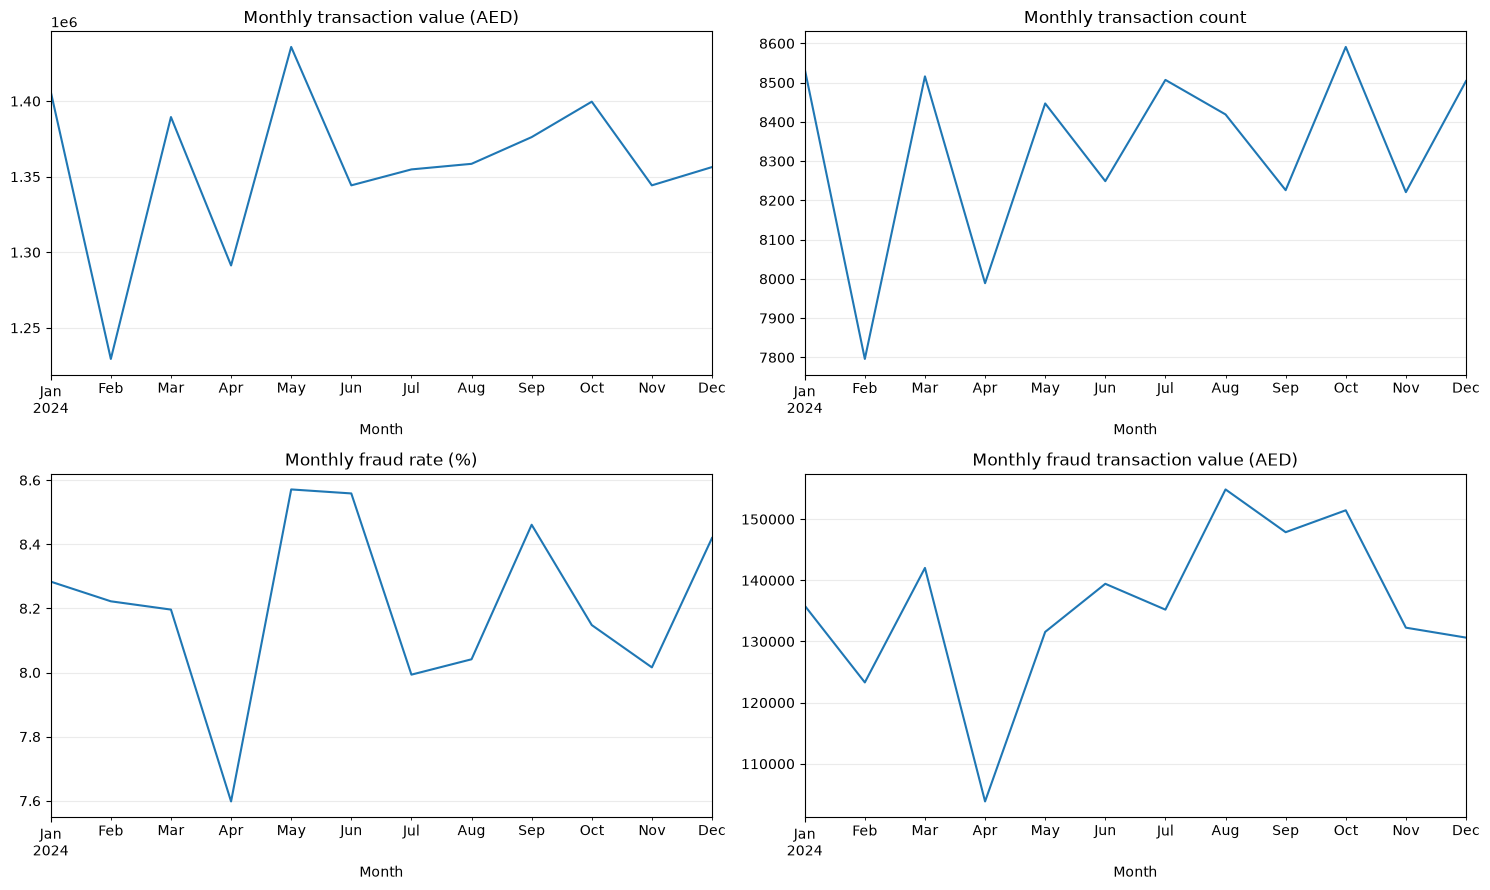

In [6]:
fig,ax=plt.subplots(2,2,figsize=(15,9))
monthly.transaction_value_aed.plot(ax=ax[0,0],title="Monthly transaction value (AED)")
monthly.transactions.plot(ax=ax[0,1],title="Monthly transaction count")
monthly.fraud_rate_pct.plot(ax=ax[1,0],title="Monthly fraud rate (%)")
monthly.fraud_value_aed.plot(ax=ax[1,1],title="Monthly fraud transaction value (AED)")
for a in ax.flat: a.grid(alpha=.25); a.set_xlabel("Month")
plt.tight_layout(); plt.show()

## 5. Fraud segmentation with Wilson confidence intervals

In [7]:
def wilson_ci(success,n,alpha=.05):
    if n==0: return np.nan,np.nan
    z=norm.ppf(1-alpha/2); p=success/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half,center+half

def fraud_by(data,col,min_rows=100,top_n=None):
    if col not in data: return pd.DataFrame()
    x=data[[col,TARGET]].copy()
    if top_n:
        keep=x[col].value_counts(dropna=False).head(top_n).index
        x=x[x[col].isin(keep)]
    rows=[]
    for group,part in x.groupby(col,dropna=False):
        n=len(part); f=int(part[TARGET].sum()); lo,hi=wilson_ci(f,n)
        rows.append({"segment":str(group),"transactions":n,"frauds":f,"fraud_rate":f/n,
                     "ci_low":lo,"ci_high":hi,"low_volume":n<min_rows})
    return pd.DataFrame(rows).sort_values("fraud_rate",ascending=False)

for col in ["payment_method","device_type","browser","merchant_category","shipping_city","bin_country","email_domain","data_source"]:
    if col in df:
        print("\n",col); display(fraud_by(df,col,100,15 if col=="email_domain" else None))


 payment_method


,segment,transactions,frauds,fraud_rate,ci_low,ci_high,low_volume
1,bank_transfer,6110,531,0.086907,0.080100,0.094232,False
3,google_pay,7858,660,0.083991,0.078059,0.090329,False
4,paypal,8027,657,0.081849,0.076050,0.088048,False
2,card,70006,5721,0.081722,0.079715,0.083774,False
0,apple_pay,7999,642,0.080260,0.074505,0.086418,False



 device_type


,segment,transactions,frauds,fraud_rate,ci_low,ci_high,low_volume
0,desktop,45063,3712,0.082374,0.079871,0.084948,False
1,mobile,50002,4110,0.082197,0.079821,0.084636,False
2,tablet,4935,389,0.078825,0.071630,0.086675,False



 browser


,segment,transactions,frauds,fraud_rate,ci_low,ci_high,low_volume
1,Edge,7028,582,0.082812,0.076594,0.089485,False
2,Firefox,12147,1002,0.082490,0.077728,0.087515,False
0,Chrome,49530,4084,0.082455,0.080065,0.084910,False
4,Safari,25126,2062,0.082066,0.078736,0.085524,False
5,Samsung Internet,4091,328,0.080176,0.072243,0.088897,False
3,Other,2078,153,0.073628,0.063169,0.085661,False


... (6 outputs left out)


 email_domain


,segment,transactions,frauds,fraud_rate,ci_low,ci_high,low_volume
7,tempmail.com,227,52,0.229075,0.179185,0.287981,False
0,10minutemail.com,209,43,0.205742,0.156486,0.265619,False
1,disposable.com,187,38,0.203209,0.151782,0.266584,False
5,mailinator.com,3341,649,0.194253,0.181192,0.208016,False
8,yahoo.com,9797,787,0.080331,0.075112,0.085879,False
9,ymail.com,2252,176,0.078153,0.067772,0.089971,False
2,gmail.com,68168,5271,0.077324,0.075342,0.079353,False
3,hotmail.com,6501,499,0.076757,0.070533,0.083481,False
4,icloud.com,4147,314,0.075717,0.068053,0.084167,False
6,outlook.com,5171,382,0.073874,0.067056,0.081323,False



 data_source


,segment,transactions,frauds,fraud_rate,ci_low,ci_high,low_volume
0,synthetic:ecom-fraud-uae-v1,100000,8211,0.08211,0.080424,0.083828,False


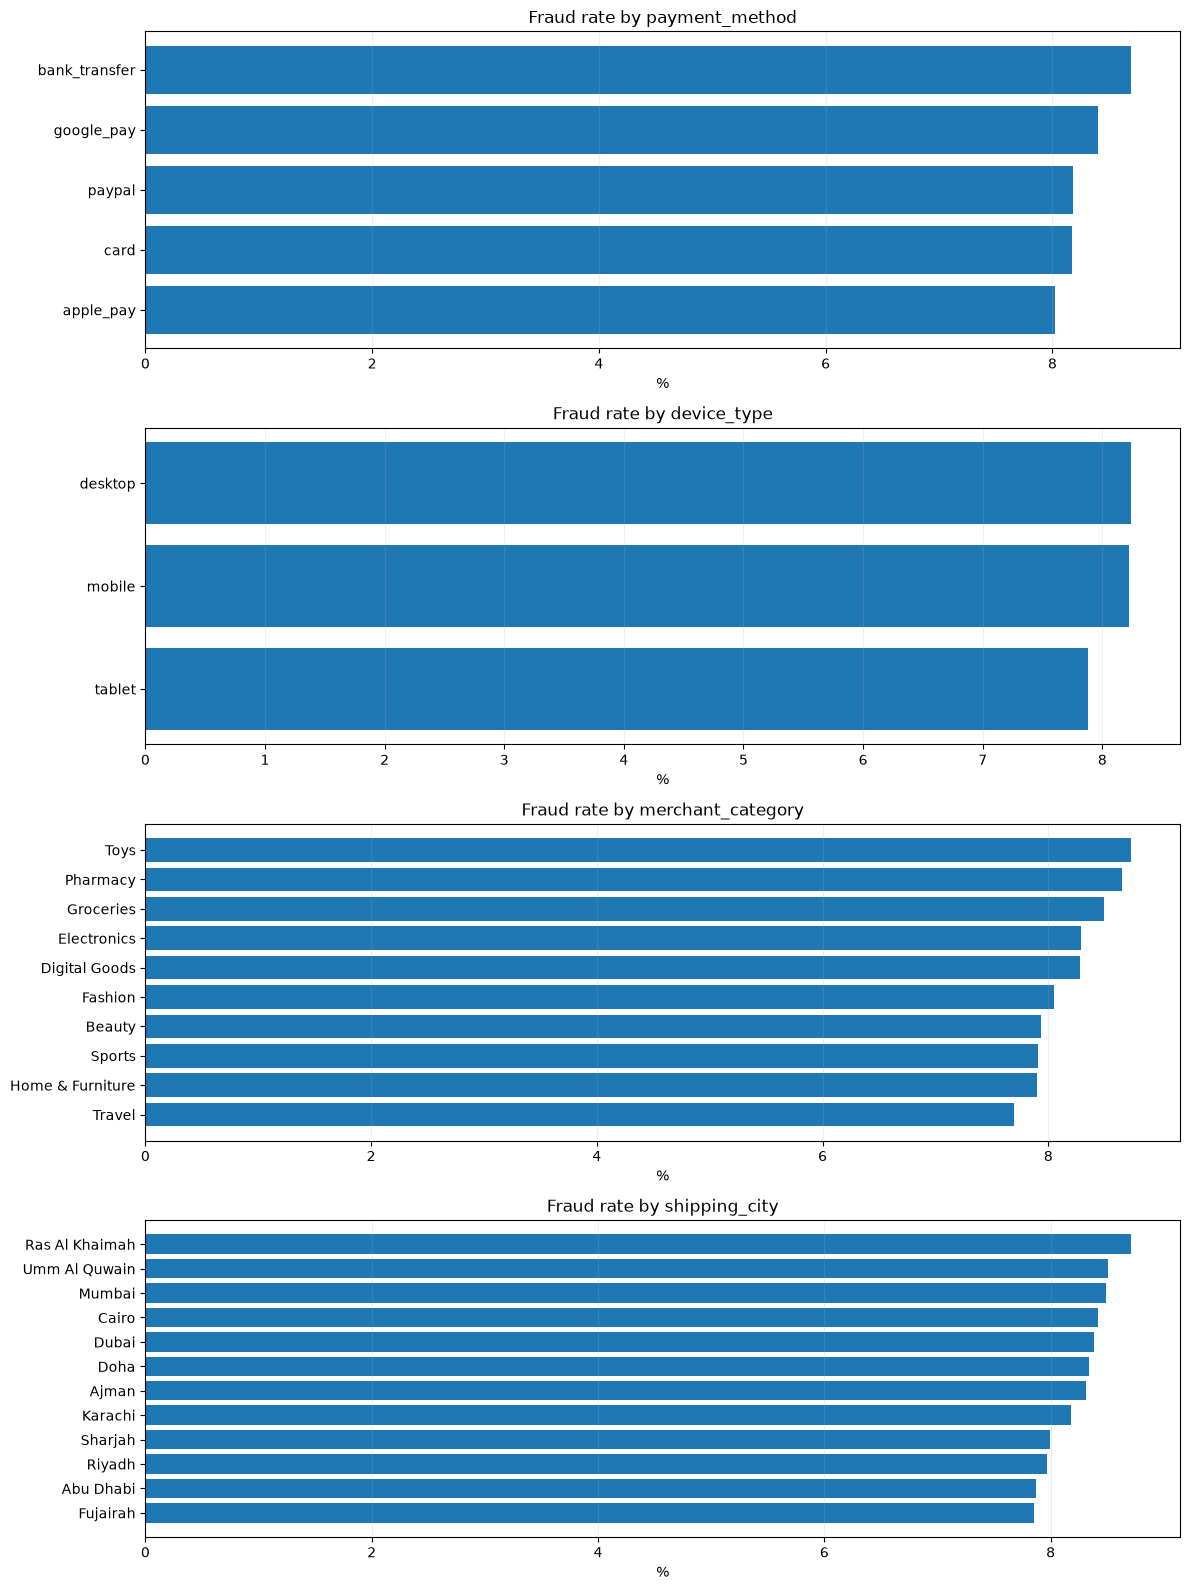

In [8]:
plot_cols=[c for c in ["payment_method","device_type","merchant_category","shipping_city"] if c in df]
fig,axes=plt.subplots(len(plot_cols),1,figsize=(12,4*len(plot_cols)))
if len(plot_cols)==1: axes=[axes]
for a,c in zip(axes,plot_cols):
    z=fraud_by(df,c); z=z[~z.low_volume].head(12).sort_values("fraud_rate")
    a.barh(z.segment,z.fraud_rate*100); a.set_title(f"Fraud rate by {c}"); a.set_xlabel("%"); a.grid(axis="x",alpha=.2)
plt.tight_layout(); plt.show()

## 6. Time patterns, amount analysis and risk bands

,count,frauds,fraud_rate
hour_utc,,,
0,4217,396,0.093906
1,4139,392,0.094709
2,4272,330,0.077247
3,4170,310,0.074341
4,4223,305,0.072224
5,4224,326,0.077178
6,4051,345,0.085164
7,4094,325,0.079384
8,4161,318,0.076424


,count,sum,mean
weekday,,,
Friday,14071,1205,0.085637
Monday,14458,1236,0.085489
Saturday,14303,1155,0.080752
Sunday,14282,1157,0.081011
Thursday,14027,1155,0.082341
Tuesday,14414,1129,0.078327
Wednesday,14445,1174,0.081274


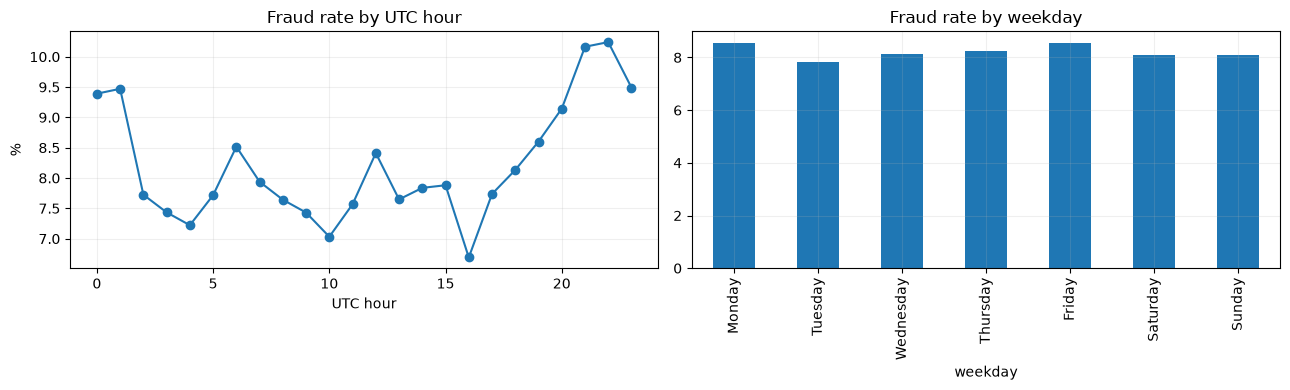

UTC hour is not UAE local hour. Convert timezone only after confirming event-time convention.


In [9]:
df["hour_utc"]=df.timestamp_utc.dt.hour
df["weekday"]=df.timestamp_utc.dt.day_name()
hourly=df.groupby("hour_utc")[TARGET].agg(["count","sum","mean"]).rename(columns={"sum":"frauds","mean":"fraud_rate"})
weekday=df.groupby("weekday")[TARGET].agg(["count","sum","mean"])
display(hourly); display(weekday)
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(hourly.index,hourly.fraud_rate*100,marker="o"); ax[0].set(title="Fraud rate by UTC hour",xlabel="UTC hour",ylabel="%")
weekday.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])["mean"].mul(100).plot(kind="bar",ax=ax[1],title="Fraud rate by weekday")
for a in ax:a.grid(alpha=.2)
plt.tight_layout();plt.show()
print("UTC hour is not UAE local hour. Convert timezone only after confirming event-time convention.")

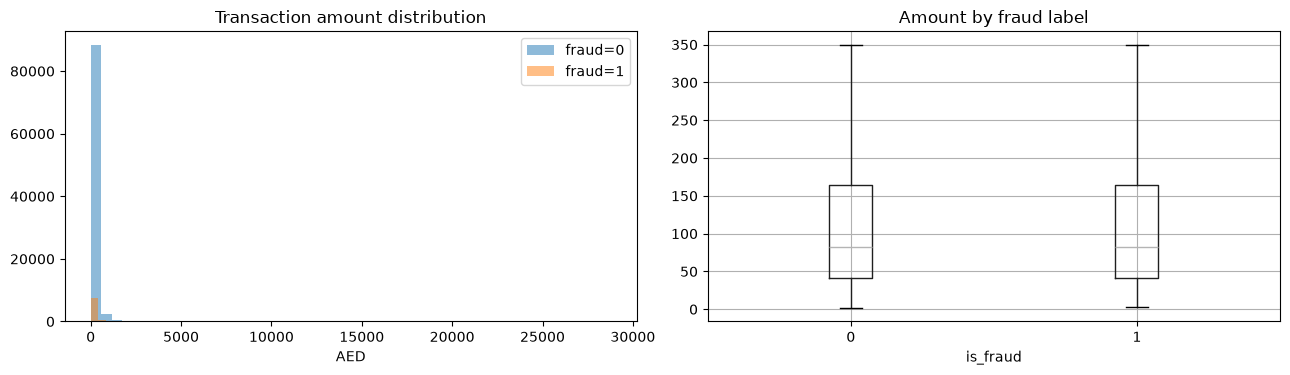

,count,frauds,fraud_rate
ip_risk_score,,,
"(-0.001, 25.5]",20010,777,0.038831
"(25.5, 34.8]",20072,1311,0.065315
"(34.8, 43.5]",19966,1590,0.079635
"(43.5, 53.7]",20106,1973,0.098130
"(53.7, 100.0]",19846,2560,0.128993


,count,frauds,fraud_rate
card_age_days,,,
"(-0.001, 173.0]",20007,1574,0.078672
"(173.0, 357.0]",20048,1626,0.081105
"(357.0, 564.0]",20026,1652,0.082493
"(564.0, 836.0]",19920,1660,0.083333
"(836.0, 2728.0]",19999,1699,0.084954


,count,frauds,fraud_rate
user_account_age_days,,,
"(-0.001, 367.0]",16700,1276,0.076407
"(367.0, 738.0]",16710,1219,0.072950
"(738.0, 1106.0]",16662,1231,0.073881
"(1106.0, 1463.0]",16661,1174,0.070464
"(1463.0, 1825.0]",16661,1193,0.071604


,count,frauds,fraud_rate
transactions_last_1h,,,
"(-0.001, 1.0]",100000,8211,0.08211


,count,frauds,fraud_rate
transactions_last_24h,,,
"(-0.001, 2.0]",100000,8211,0.08211


In [10]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
for label,g in df.groupby(TARGET): ax[0].hist(g.amount_aed.dropna(),bins=50,alpha=.5,label=f"fraud={label}")
ax[0].set(title="Transaction amount distribution",xlabel="AED");ax[0].legend()
df.boxplot(column="amount_aed",by=TARGET,ax=ax[1],showfliers=False);ax[1].set_title("Amount by fraud label")
plt.suptitle("");plt.tight_layout();plt.show()
for c in ["ip_risk_score","card_age_days","user_account_age_days","transactions_last_1h","transactions_last_24h"]:
    if c in df:
        bands=pd.qcut(df[c],5,duplicates="drop")
        display(df.groupby(bands,observed=False)[TARGET].agg(["count","sum","mean"]).rename(columns={"sum":"frauds","mean":"fraud_rate"}))

## 7. Correlation and statistical tests

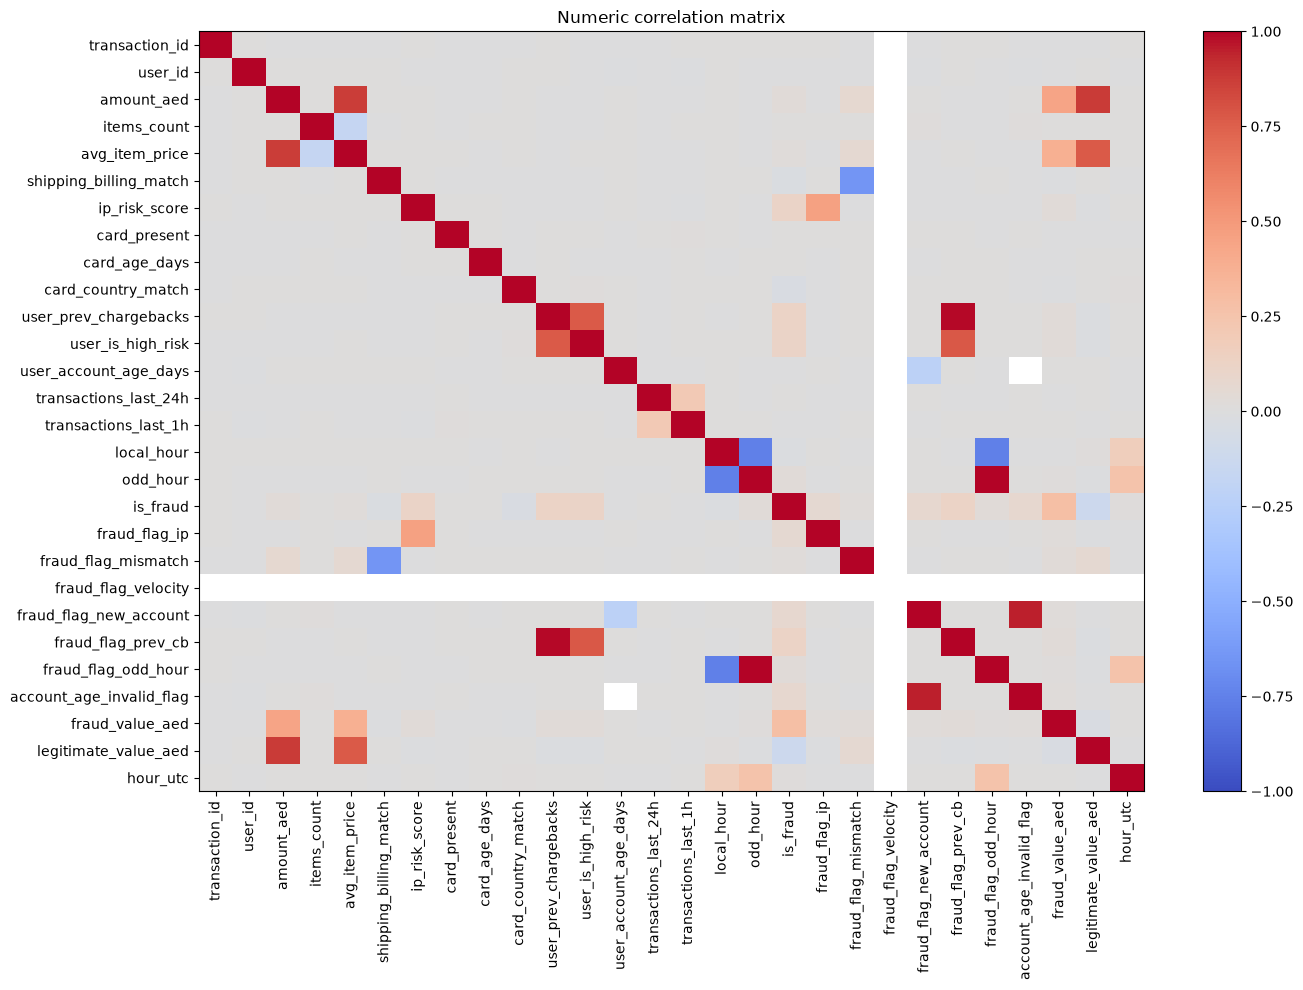

,correlation_with_fraud
is_fraud,1.000000
fraud_value_aed,0.286264
fraud_flag_prev_cb,0.121494
user_prev_chargebacks,0.119735
ip_risk_score,0.116704
user_is_high_risk,0.114228
fraud_flag_new_account,0.076544
account_age_invalid_flag,0.073851
fraud_flag_ip,0.054778
odd_hour,0.030257


,feature,test,statistic,p_value,n,fraud_median,legit_median
0,shipping_billing_match,chi-square,7.904117e+01,6.082907e-19,100000,NaN,NaN
1,card_country_match,chi-square,1.178163e+02,1.902142e-27,100000,NaN,NaN
2,ip_risk_score,Mann-Whitney U,4.667125e+08,1.233027e-281,100000,45.7,38.6
3,transactions_last_24h,Mann-Whitney U,3.769166e+08,8.527320e-01,100000,0.0,0.0
4,user_account_age_days,Mann-Whitney U,2.317202e+08,3.681624e-02,83394,899.0,921.0


In [11]:
num=df.select_dtypes(include=np.number)
if TARGET in num and num.shape[1]>1:
    corr=num.corr()
    plt.figure(figsize=(14,10));plt.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm",aspect="auto")
    plt.colorbar();plt.xticks(range(len(corr)),corr.columns,rotation=90);plt.yticks(range(len(corr)),corr.columns)
    plt.title("Numeric correlation matrix");plt.tight_layout();plt.show()
    display(corr[TARGET].sort_values(ascending=False).to_frame("correlation_with_fraud"))

# Five hypothesis examples. Tests are associations, not causal proof.
hypothesis_rows=[]
for c in ["shipping_billing_match","card_country_match"]:
    if c in df:
        tab=pd.crosstab(df[c],df[TARGET])
        chi2,p,dof,expected=chi2_contingency(tab)
        hypothesis_rows.append({"feature":c,"test":"chi-square","statistic":chi2,"p_value":p,"n":int(tab.values.sum())})
for c in ["ip_risk_score","transactions_last_24h","user_account_age_days"]:
    if c in df:
        a=df.loc[df[TARGET]==1,c].dropna();b=df.loc[df[TARGET]==0,c].dropna()
        if len(a) and len(b):
            stat,p=mannwhitneyu(a,b,alternative="two-sided")
            hypothesis_rows.append({"feature":c,"test":"Mann-Whitney U","statistic":stat,"p_value":p,"fraud_median":a.median(),"legit_median":b.median(),"n":len(a)+len(b)})
display(pd.DataFrame(hypothesis_rows))

## 8. Rule-engine performance and overlap

,rule,flagged,TP,FP,FN,TN,precision,recall,FPR,lift,fraud_value_caught_AED,legitimate_value_flagged_AED
0,fraud_flag_ip,3552,570,2982,7641,88807,0.160473,0.069419,0.032488,1.954366,117518.94,454570.02
1,fraud_flag_mismatch,3155,351,2804,7860,88985,0.111252,0.042748,0.030548,1.354914,139867.65,837920.64
2,fraud_flag_velocity,0,0,0,8211,91789,0.000000,0.000000,0.000000,0.000000,0.00,0.00
3,fraud_flag_new_account,18017,2287,15730,5924,76059,0.126936,0.278529,0.171371,1.545922,413413.34,2564165.28
4,fraud_flag_prev_cb,2981,812,2169,7399,89620,0.272392,0.098892,0.023630,3.317401,148178.52,330501.73
5,fraud_flag_odd_hour,25041,2416,22625,5795,69164,0.096482,0.294239,0.246489,1.175031,477742.42,3532300.34
6,any_flag,44279,4955,39324,3256,52465,0.111904,0.603459,0.428417,1.362855,997346.11,6465525.23
7,2plus_flags,7923,1335,6588,6876,85201,0.168497,0.162587,0.071773,2.052086,271925.83,1171935.74
8,3plus_flags,532,141,391,8070,91398,0.265038,0.017172,0.004260,3.227836,26017.46,80910.09


,fraud_flag_ip,fraud_flag_mismatch,fraud_flag_velocity,fraud_flag_new_account,fraud_flag_prev_cb,fraud_flag_odd_hour
fraud_flag_ip,3552,95,0,645,89,854
fraud_flag_mismatch,95,3155,0,564,105,822
fraud_flag_velocity,0,0,0,0,0,0
fraud_flag_new_account,645,564,0,18017,553,4515
fraud_flag_prev_cb,89,105,0,553,2981,781
fraud_flag_odd_hour,854,822,0,4515,781,25041


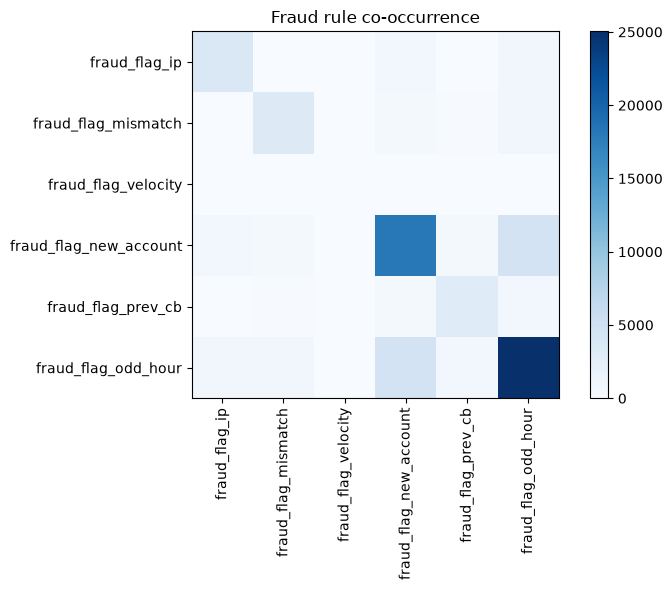

In [12]:
available_flags=[c for c in FLAG_COLS if c in df]
def rule_metrics(mask,y,amount):
    mask=pd.Series(mask,index=y.index).fillna(False).astype(bool); y=pd.Series(y,index=mask.index).astype(int)
    amount=pd.Series(amount,index=mask.index).fillna(0)
    tp=int((mask & y.eq(1)).sum());fp=int((mask & y.eq(0)).sum())
    fn=int((~mask & y.eq(1)).sum());tn=int((~mask & y.eq(0)).sum())
    return {"flagged":int(mask.sum()),"TP":tp,"FP":fp,"FN":fn,"TN":tn,
      "precision":tp/max(tp+fp,1),"recall":tp/max(tp+fn,1),
      "FPR":fp/max(fp+tn,1),"lift":(tp/max(mask.sum(),1))/max(y.mean(),1e-12),
      "fraud_value_caught_AED":amount[mask & y.eq(1)].sum(),
      "legitimate_value_flagged_AED":amount[mask & y.eq(0)].sum()}
rule_rows=[]
for c in available_flags: rule_rows.append({"rule":c,**rule_metrics(df[c].astype(bool),df[TARGET],df.amount_aed)})
if available_flags:
    flag_count=df[available_flags].fillna(0).astype(int).sum(axis=1)
    for name,mask in [("any_flag",flag_count>=1),("2plus_flags",flag_count>=2),("3plus_flags",flag_count>=3)]:
        rule_rows.append({"rule":name,**rule_metrics(mask,df[TARGET],df.amount_aed)})
rule_performance=pd.DataFrame(rule_rows);display(rule_performance)
if available_flags:
    overlap=df[available_flags].astype(int).T.dot(df[available_flags].astype(int))
    display(overlap)
    plt.figure(figsize=(8,6));plt.imshow(overlap,cmap="Blues");plt.colorbar()
    plt.xticks(range(len(available_flags)),available_flags,rotation=90);plt.yticks(range(len(available_flags)),available_flags)
    plt.title("Fraud rule co-occurrence");plt.tight_layout();plt.show()

## 9. Leakage audit before predictive modeling

In [13]:
leakage_rows=[]
for c in df.columns:
    if c==TARGET: continue
    if c.startswith("fraud_flag_"):
        risk,known,reason="HIGH","No / unverified","Rule output may re-encode label or decision; exclude from predictors."
    elif c in ["user_prev_chargebacks","user_is_high_risk","transactions_last_1h","transactions_last_24h","ip_risk_score"]:
        risk,known,reason="HIGH","Unverified","Prove the feature was calculated strictly before authorization."
    elif c in ["transaction_id","user_id","ip_address","data_source"]:
        risk,known,reason="HIGH","Not used","Identifier/source can cause memorization or source leakage."
    elif c in ["timestamp_utc","local_hour","odd_hour"]:
        risk,known,reason="MEDIUM","Potentially","Confirm timezone and derive only from transaction event time."
    else:
        risk,known,reason="LOW/MEDIUM","Likely","Confirm source timestamp and business definition."
    leakage_rows.append({"feature":c,"known_at_decision_time":known,"leakage_risk":risk,"reason":reason})
leakage_table=pd.DataFrame(leakage_rows);display(leakage_table)

,feature,known_at_decision_time,leakage_risk,reason
0,transaction_id,Not used,HIGH,Identifier/source can cause memorization or so...
1,user_id,Not used,HIGH,Identifier/source can cause memorization or so...
2,timestamp_utc,Potentially,MEDIUM,Confirm timezone and derive only from transact...
3,amount_aed,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.
4,currency,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.
5,payment_method,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.
6,device_type,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.
7,browser,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.
8,merchant_category,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.
9,items_count,Likely,LOW/MEDIUM,Confirm source timestamp and business definition.


## 10. Supervised machine learning — chronological split and feature pipeline

In [14]:
work=df.sort_values("timestamp_utc").reset_index(drop=True).copy()
n=len(work);i1=int(.70*n);i2=int(.85*n)
train=work.iloc[:i1].copy();valid=work.iloc[i1:i2].copy();test=work.iloc[i2:].copy()
excluded=[TARGET,"timestamp_utc","transaction_id","user_id","ip_address","data_source"]+available_flags
excluded=[c for c in excluded if c in work]
feature_cols=[c for c in work.columns if c not in excluded and c not in ["fraud_value_aed","legitimate_value_aed"]]
X_train=train[feature_cols].copy();y_train=train[TARGET].astype(int)
X_valid=valid[feature_cols].copy();y_valid=valid[TARGET].astype(int)
X_test=test[feature_cols].copy();y_test=test[TARGET].astype(int)
for X,t in [(X_train,train.timestamp_utc),(X_valid,valid.timestamp_utc),(X_test,test.timestamp_utc)]:
    X["event_hour_utc"]=t.dt.hour.to_numpy()
    X["event_dayofweek"]=t.dt.dayofweek.to_numpy()
numeric_features=X_train.select_dtypes(include=["number","bool"]).columns.tolist()
categorical_features=[c for c in X_train.columns if c not in numeric_features]
numeric_pipe=Pipeline([("imputer",SimpleImputer(strategy="median",add_indicator=True)),("scale",StandardScaler(with_mean=False))])
categorical_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])
transformers=[]
if numeric_features: transformers.append(("num",numeric_pipe,numeric_features))
if categorical_features: transformers.append(("cat",categorical_pipe,categorical_features))
preprocessor=ColumnTransformer(transformers=transformers,remainder="drop")
print("Train/valid/test:",X_train.shape,X_valid.shape,X_test.shape)
print("Preprocessor ready.")

Train/valid/test: (70000, 29) (15000, 29) (15000, 29)
Preprocessor ready.


In [15]:
models={
"Dummy prior":DummyClassifier(strategy="prior"),
"Logistic Regression":LogisticRegression(max_iter=1200,class_weight="balanced",solver="liblinear",random_state=RANDOM_STATE),
"Random Forest":RandomForestClassifier(n_estimators=120,min_samples_leaf=4,class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE),
"HistGradientBoosting":HistGradientBoostingClassifier(max_iter=100,learning_rate=.07,max_leaf_nodes=15,random_state=RANDOM_STATE)
}
try:
    from xgboost import XGBClassifier
    scale_pos=y_train.eq(0).sum()/max(y_train.eq(1).sum(),1)
    models["XGBoost"]=XGBClassifier(n_estimators=120,max_depth=4,learning_rate=.05,scale_pos_weight=scale_pos,
                                    eval_metric="logloss",n_jobs=2,random_state=RANDOM_STATE)
except Exception: print("XGBoost not installed; skipped.")
fitted_models={};valid_probabilities={};rows=[]
for name,est in models.items():
    print("Training:",name)
    pipe=Pipeline([("preprocess",clone(preprocessor)),("model",est)])
    pipe.fit(X_train,y_train)
    prob=pipe.predict_proba(X_valid)[:,1]
    fitted_models[name]=pipe;valid_probabilities[name]=prob
    rows.append({"model":name,"validation_PR_AUC":average_precision_score(y_valid,prob),
                 "validation_ROC_AUC":roc_auc_score(y_valid,prob)})
model_comparison=pd.DataFrame(rows).sort_values("validation_PR_AUC",ascending=False)
display(model_comparison)
best_name=model_comparison.iloc[0]["model"];best_pipeline=fitted_models[best_name]
best_val_prob=valid_probabilities[best_name]
print("Selected model:",best_name)

Training: Dummy prior
Training: Logistic Regression
Training: Random Forest
Training: HistGradientBoosting
Training: XGBoost


,model,validation_PR_AUC,validation_ROC_AUC
1,Logistic Regression,0.179251,0.693506
4,XGBoost,0.174647,0.688079
3,HistGradientBoosting,0.171108,0.688852
2,Random Forest,0.153889,0.669099
0,Dummy prior,0.082200,0.500000


Selected model: Logistic Regression


## 11. Threshold, test evaluation and calibration

Validation threshold: 0.525232558245785


,test_metrics
ROC_AUC,0.699909
PR_AUC,0.166882
precision,0.152445
recall,0.531778
F1,0.236960
F2,0.355071
Brier,0.216708
review_rate,0.289067


,pred_legit,pred_fraud
actual_legit,10082,3675
actual_fraud,582,661


              precision    recall  f1-score   support

           0       0.95      0.73      0.83     13757
           1       0.15      0.53      0.24      1243

    accuracy                           0.72     15000
   macro avg       0.55      0.63      0.53     15000
weighted avg       0.88      0.72      0.78     15000



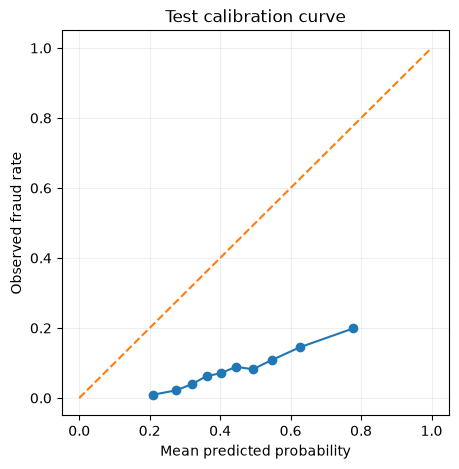

In [16]:
precision,recall,thresholds=precision_recall_curve(y_valid,best_val_prob)
f2=(5*precision[:-1]*recall[:-1])/(4*precision[:-1]+recall[:-1]+1e-12)
MAX_REVIEW_RATE=.30  # illustrative capacity assumption
rates=np.array([(best_val_prob>=t).mean() for t in thresholds])
eligible=np.where(rates<=MAX_REVIEW_RATE)[0]
selected_threshold=float(thresholds[eligible[np.argmax(f2[eligible])]]) if len(eligible) else float(np.quantile(best_val_prob,1-MAX_REVIEW_RATE))
print("Validation threshold:",selected_threshold)
test_prob=best_pipeline.predict_proba(X_test)[:,1]
test_pred=(test_prob>=selected_threshold).astype(int)
test_metrics={"ROC_AUC":roc_auc_score(y_test,test_prob),"PR_AUC":average_precision_score(y_test,test_prob),
 "precision":precision_score(y_test,test_pred,zero_division=0),"recall":recall_score(y_test,test_pred,zero_division=0),
 "F1":f1_score(y_test,test_pred,zero_division=0),"F2":fbeta_score(y_test,test_pred,beta=2,zero_division=0),
 "Brier":brier_score_loss(y_test,test_prob),"review_rate":test_pred.mean()}
display(pd.Series(test_metrics).to_frame("test_metrics"))
display(pd.DataFrame(confusion_matrix(y_test,test_pred),index=["actual_legit","actual_fraud"],columns=["pred_legit","pred_fraud"]))
print(classification_report(y_test,test_pred,zero_division=0))
frac,meanp=calibration_curve(y_test,test_prob,n_bins=10,strategy="quantile")
plt.figure(figsize=(5,5));plt.plot(meanp,frac,marker="o");plt.plot([0,1],[0,1],"--")
plt.title("Test calibration curve");plt.xlabel("Mean predicted probability");plt.ylabel("Observed fraud rate");plt.grid(alpha=.2);plt.show()

## 12. Unsupervised learning — anomaly detection and clustering

In [17]:
# Numeric unsupervised features; target and identifiers excluded.
unsup_cols=[c for c in X_train.select_dtypes(include=np.number).columns if c!=TARGET]
MAX_UNSUP=10000
sample=X_train[unsup_cols].sample(min(MAX_UNSUP,len(X_train)),random_state=RANDOM_STATE)
unsup_prep=Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())])
Z=unsup_prep.fit_transform(sample)
eval_idx=X_test.sample(min(4000,len(X_test)),random_state=RANDOM_STATE).index
Z_eval=unsup_prep.transform(X_test.loc[eval_idx,unsup_cols])
y_eval=y_test.loc[eval_idx]
iso=IsolationForest(n_estimators=120,contamination="auto",random_state=RANDOM_STATE,n_jobs=-1)
iso.fit(Z); anomaly_score=-iso.decision_function(Z_eval)
anomaly_flag=iso.predict(Z_eval)==-1
print("Isolation Forest anomaly fraction:",anomaly_flag.mean())
print("Fraud rate among anomalies:",y_eval[anomaly_flag].mean() if anomaly_flag.any() else np.nan)
print("Anomaly score ROC-AUC:",roc_auc_score(y_eval,anomaly_score))
print("Anomaly score PR-AUC:",average_precision_score(y_eval,anomaly_score))

Isolation Forest anomaly fraction: 0.176
Fraud rate among anomalies: 0.11789772727272728
Anomaly score ROC-AUC: 0.6066404574454791
Anomaly score PR-AUC: 0.11948347197341698


In [18]:
# KMeans clusters are exploratory customer/transaction segments, not fraud labels.
km=KMeans(n_clusters=4,n_init=10,random_state=RANDOM_STATE)
labels=km.fit_predict(Z)
cluster_df=sample.copy();cluster_df["cluster"]=labels
display(cluster_df.groupby("cluster").mean(numeric_only=True))

,amount_aed,items_count,avg_item_price,shipping_billing_match,ip_risk_score,card_present,card_age_days,card_country_match,user_prev_chargebacks,user_is_high_risk,user_account_age_days,transactions_last_24h,transactions_last_1h,local_hour,odd_hour,account_age_invalid_flag,hour_utc,event_hour_utc,event_dayofweek
cluster,,,,,,,,,,,,,,,,,,,
0,164.468201,2.212986,93.971268,0.933047,40.479535,0.027539,516.907276,0.603335,0.000000,0.021475,923.365734,0.007580,0.000505,8.507074,0.201617,0.178626,4.507074,4.507074,3.003790
1,163.987727,2.188063,96.780728,0.926675,39.896151,0.040438,516.286236,0.609257,0.000000,0.019732,907.517322,0.010231,0.000000,18.372960,0.000000,0.163216,14.372960,14.372960,2.957125
2,166.731895,2.170277,96.801372,0.934416,40.186282,0.023466,530.859206,0.610108,0.000000,0.019856,898.337838,0.007220,0.000000,1.474128,1.000000,0.154031,21.474128,21.474128,2.938628
3,147.930691,2.305455,76.950073,0.960000,39.024000,0.029091,553.520000,0.672727,1.007273,1.000000,936.125561,0.003636,0.003636,11.698182,0.272727,0.189091,12.236364,12.236364,2.872727


## 13. Deep learning — optional CPU PyTorch MLP

A small numeric-only MLP is trained on the training partition and evaluated on validation/test partitions. It is an experiment; it is not assumed to outperform tree-based models. If PyTorch is unavailable, this section skips cleanly.

In [19]:
try:
    import torch
    from torch import nn
    from torch.utils.data import TensorDataset,DataLoader
    torch_available=True
except Exception as e:
    torch_available=False
    print("PyTorch unavailable; skipped:",repr(e))

if torch_available:
    dl_cols=numeric_features
    imp=SimpleImputer(strategy="median")
    A=imp.fit_transform(X_train[dl_cols]);B=imp.transform(X_valid[dl_cols]);D=imp.transform(X_test[dl_cols])
    sc=StandardScaler();A=sc.fit_transform(A).astype("float32");B=sc.transform(B).astype("float32");D=sc.transform(D).astype("float32")
    torch.manual_seed(RANDOM_STATE)
    class TabularMLP(nn.Module):
        def __init__(self,n):
            super().__init__()
            self.net=nn.Sequential(nn.Linear(n,48),nn.ReLU(),nn.Dropout(.2),nn.Linear(48,16),nn.ReLU(),nn.Linear(16,1))
        def forward(self,x): return self.net(x).squeeze(1)
    net=TabularMLP(A.shape[1])
    pw=torch.tensor([y_train.eq(0).sum()/max(y_train.eq(1).sum(),1)],dtype=torch.float32)
    loss_fn=nn.BCEWithLogitsLoss(pos_weight=pw);opt=torch.optim.Adam(net.parameters(),lr=.001)
    loader=DataLoader(TensorDataset(torch.tensor(A),torch.tensor(y_train.to_numpy(dtype="float32"))),batch_size=512,shuffle=True)
    for epoch in range(6):
        net.train();losses=[]
        for xb,yb in loader:
            opt.zero_grad();loss=loss_fn(net(xb),yb);loss.backward();opt.step();losses.append(loss.item())
        print("Epoch",epoch+1,"loss",round(float(np.mean(losses)),4))
    net.eval()
    with torch.no_grad():
        dl_valid=torch.sigmoid(net(torch.tensor(B))).numpy()
        dl_test=torch.sigmoid(net(torch.tensor(D))).numpy()
    print("DL validation PR-AUC:",average_precision_score(y_valid,dl_valid))
    print("DL test PR-AUC:",average_precision_score(y_test,dl_test))
else:
    print("Install PyTorch to run this optional experiment.")

Epoch 1 loss 1.2218
Epoch 2 loss 1.1811
Epoch 3 loss 1.174
Epoch 4 loss 1.1686
Epoch 5 loss 1.1668
Epoch 6 loss 1.1679
DL validation PR-AUC: 0.1750708893015619
DL test PR-AUC: 0.16250694707892063


## 14. NLP — genuine text availability check

The expected 36-column dataset contains categorical values but no obvious long-form text corpus. Email domains, browser names and city names are not sufficient evidence for a meaningful NLP task. The notebook will only train a text classifier if genuine free-text fields exist (e.g. customer message, product description, chargeback narrative). Post-event chargeback narratives must not be used to predict the original authorization decision.

In [20]:
text_cols=[]
for c in df.select_dtypes(include=["object","string"]).columns:
    if c in ["transaction_id","user_id","ip_address","data_source","timestamp_utc"]: continue
    avg=df[c].dropna().astype(str).str.len().mean()
    if pd.notna(avg) and avg>=25 and df[c].nunique(dropna=True)>=20: text_cols.append(c)
print("Potential genuine text columns:",text_cols)
if text_cols:
    c=text_cols[0]
    txt=df[[c,TARGET,"timestamp_utc"]].dropna().sort_values("timestamp_utc")
    cut=int(.8*len(txt));tr=txt.iloc[:cut];te=txt.iloc[cut:]
    vec=TfidfVectorizer(max_features=4000,ngram_range=(1,2),min_df=2)
    Xt=vec.fit_transform(tr[c].astype(str));Xe=vec.transform(te[c].astype(str))
    nlp=MultinomialNB().fit(Xt,tr[TARGET]);p=nlp.predict_proba(Xe)[:,1]
    print("Text field:",c,"NLP PR-AUC:",average_precision_score(te[TARGET],p))
else:
    print("NLP not trained: no suitable free-text field in this dataset. This is the correct conclusion.")

Potential genuine text columns: []
NLP not trained: no suitable free-text field in this dataset. This is the correct conclusion.


## 15. Cost-based operating policy

In [23]:

# ==============================================
# PHASE 15 — COST-BASED OPERATING POLICY
# FIX: ALIGN ALL ARRAY LENGTHS
# ==============================================

import numpy as np
import pandas as pd

# Business assumptions (illustrative only)
CHARGEBACK_FEE_AED = 25.0
REVIEW_COST_AED = 8.0
MARGIN_RATE = 0.20

print("Chargeback fee AED:", CHARGEBACK_FEE_AED)
print("Review cost AED:", REVIEW_COST_AED)
print("Margin rate:", MARGIN_RATE)

# 1. Align actual labels, transaction amounts and predictions
# All must refer to exactly the same test rows.

cost_test = test.loc[X_test.index].copy()

cost_test["actual_fraud"] = y_test.loc[cost_test.index]
cost_test["predicted_probability"] = test_prob

# Verify lengths
assert len(cost_test) == len(y_test)
assert len(cost_test) == len(test_prob)

# 2. Calculate transaction values
cost_test["amount_aed"] = pd.to_numeric(
    cost_test["amount_aed"], errors="coerce"
).fillna(0)

actual = cost_test["actual_fraud"].to_numpy(dtype=int)
amount = cost_test["amount_aed"].to_numpy(dtype=float)
probability = cost_test["predicted_probability"].to_numpy(dtype=float)

# 3. Define cost calculation
def policy_cost(
    y,
    amount,
    decision,
    chargeback_fee,
    review_cost,
    margin_rate
):
    y = np.asarray(y)
    amount = np.asarray(amount)
    decision = np.asarray(decision)

    if not (len(y) == len(amount) == len(decision)):
        raise ValueError("Labels, amounts and decisions must have equal lengths.")

    # Decision: 0 = Approve, 1 = Decline, 2 = Manual Review
    missed_fraud = (y == 1) & (decision == 0)

    false_decline = (y == 0) & (decision == 1)

    manual_review = (decision == 2)

    missed_fraud_cost = (
        amount[missed_fraud].sum()
        + chargeback_fee * missed_fraud.sum()
    )

    false_decline_cost = (
        amount[false_decline].sum() * margin_rate
    )

    review_expense = (
        manual_review.sum() * review_cost
    )

    total_cost = (
        missed_fraud_cost
        + false_decline_cost
        + review_expense
    )

    return {
        "missed_fraud_cost": missed_fraud_cost,
        "false_decline_cost": false_decline_cost,
        "review_cost": review_expense,
        "total_cost": total_cost
    }

# 4. Policy A — Approve all transactions
approve_all = np.zeros(len(actual), dtype=int)

# 5. Policy B — Existing fraud rules
if available_flags:
    rule_flags = (
        cost_test[available_flags]
        .fillna(0)
        .astype(int)
        .sum(axis=1)
        .to_numpy()
    )

    rule_decision = np.where(rule_flags >= 1, 1, 0)
else:
    rule_decision = np.zeros(len(actual), dtype=int)

# 6. Policy C — ML model with manual review
model_decision = np.where(
    probability >= selected_threshold,
    2,
    0
)

# 7. Compare policies
policies = {
    "Approve All": approve_all,
    "Existing Fraud Rules": rule_decision,
    "ML Model - Manual Review": model_decision
}

results = []

for policy_name, decisions in policies.items():

    result = policy_cost(
        y=actual,
        amount=amount,
        decision=decisions,
        chargeback_fee=CHARGEBACK_FEE_AED,
        review_cost=REVIEW_COST_AED,
        margin_rate=MARGIN_RATE
    )

    results.append({
        "Policy": policy_name,
        "Transactions": len(decisions),
        "Flagged_or_Reviewed": int((decisions != 0).sum()),
        "Missed_Fraud_Cost_AED": result["missed_fraud_cost"],
        "False_Decline_Cost_AED": result["false_decline_cost"],
        "Review_Cost_AED": result["review_cost"],
        "Total_Estimated_Cost_AED": result["total_cost"]
    })

cost_comparison = pd.DataFrame(results)

display(
    cost_comparison.sort_values(
        "Total_Estimated_Cost_AED"
    )
)

print("\nSUCCESS: Cost-based policy comparison completed.")
print("Aligned test records:", len(actual))


Chargeback fee AED: 25.0
Review cost AED: 8.0
Margin rate: 0.2


,Policy,Transactions,Flagged_or_Reviewed,Missed_Fraud_Cost_AED,False_Decline_Cost_AED,Review_Cost_AED,Total_Estimated_Cost_AED
2,ML Model - Manual Review,15000,4336,98029.38,0.000,34688.0,132717.380
0,Approve All,15000,0,267589.89,0.000,0.0,267589.890
1,Existing Fraud Rules,15000,6665,113976.79,191785.178,0.0,305761.968



SUCCESS: Cost-based policy comparison completed.
Aligned test records: 15000


## 16. SQLite SQL cross-check

In [24]:
df_sql=df.copy()
df_sql["timestamp_utc"]=df_sql.timestamp_utc.dt.strftime("%Y-%m-%dT%H:%M:%SZ")
conn=sqlite3.connect(REPORT_DIR/"fraud_clean.db")
df_sql.to_sql("transactions",conn,if_exists="replace",index=False)
sql_count=pd.read_sql_query("SELECT COUNT(*) n FROM transactions",conn).iloc[0,0]
assert sql_count==len(df_sql)
q1=("SELECT payment_method, device_type, COUNT(*) transactions, SUM(is_fraud) frauds, "
    "ROUND(100.0*SUM(is_fraud)/COUNT(*),3) fraud_rate_pct, "
    "ROUND(SUM(CASE WHEN is_fraud=1 THEN amount_aed ELSE 0 END),2) fraud_value_aed "
    "FROM transactions GROUP BY payment_method,device_type ORDER BY fraud_value_aed DESC")
display(pd.read_sql_query(q1,conn))

,payment_method,device_type,transactions,frauds,fraud_rate_pct,fraud_value_aed
0,card,mobile,35014,2875,8.211,535717.17
1,card,desktop,31565,2579,8.170,500582.57
2,apple_pay,mobile,4017,312,7.767,80340.83
3,paypal,mobile,4034,321,7.957,74121.63
4,google_pay,desktop,3624,298,8.223,71131.37
5,bank_transfer,mobile,3079,268,8.704,68678.11
6,card,tablet,3427,267,7.791,64730.27
7,paypal,desktop,3570,296,8.291,58462.10
8,google_pay,mobile,3858,334,8.657,58043.23
9,apple_pay,desktop,3596,299,8.315,53045.86


In [25]:
q2=("WITH x AS (SELECT user_id,timestamp_utc,LAG(timestamp_utc) OVER "
    "(PARTITION BY user_id ORDER BY timestamp_utc) prev_ts FROM transactions), "
    "g AS (SELECT user_id,(julianday(timestamp_utc)-julianday(prev_ts))*1440 gap_min "
    "FROM x WHERE prev_ts IS NOT NULL) SELECT COUNT(*) gaps_under_5m FROM g WHERE gap_min<5")
q3=("SELECT user_id,COUNT(*) transactions,SUM(is_fraud) frauds,"
    "SUM(CASE WHEN is_fraud=1 THEN amount_aed ELSE 0 END) fraud_value_aed,"
    "MIN(timestamp_utc) first_tx,MAX(timestamp_utc) last_tx FROM transactions "
    "GROUP BY user_id ORDER BY fraud_value_aed DESC LIMIT 20")
display(pd.read_sql_query(q2,conn));display(pd.read_sql_query(q3,conn))
conn.close()

,gaps_under_5m
0,3


,user_id,transactions,frauds,fraud_value_aed,first_tx,last_tx
0,1004534,5,1,20929.35,2024-02-14T05:27:58Z,2024-11-24T09:28:09Z
1,1018323,4,1,16563.34,2024-03-10T02:07:26Z,2024-12-10T04:37:54Z
2,1021972,4,2,12438.15,2024-06-26T21:19:50Z,2024-12-21T04:03:27Z
3,1015399,4,1,12262.54,2024-01-09T22:40:28Z,2024-08-27T00:10:43Z
4,1014592,7,1,11259.49,2024-01-04T11:50:34Z,2024-12-17T01:53:53Z
5,1028038,7,1,11074.62,2024-01-21T13:48:17Z,2024-11-11T07:59:50Z
6,1016263,5,1,10846.79,2024-01-31T19:00:58Z,2024-08-29T22:02:33Z
7,1011293,4,2,10547.52,2024-01-21T15:24:39Z,2024-10-29T20:22:47Z
8,1019383,2,1,10068.30,2024-03-13T00:28:36Z,2024-10-14T04:28:24Z
9,1026590,3,1,9377.28,2024-05-20T03:31:54Z,2024-10-19T15:15:05Z


## 17. Segment performance and drift (PSI)

In [26]:
seg=test.copy();seg["y_true"]=y_test.to_numpy();seg["y_pred"]=test_pred
cm=confusion_matrix(y_test,test_pred,labels=[0,1]);overall_fpr=cm[0,1]/max(cm[0].sum(),1)
rows=[]
for c in ["payment_method","device_type","shipping_city","data_source"]:
    if c not in seg: continue
    for g,p in seg.groupby(c,dropna=False):
        if len(p)<100: continue
        tn,fp,fn,tp=confusion_matrix(p.y_true,p.y_pred,labels=[0,1]).ravel()
        fpr=fp/max(fp+tn,1);rec=tp/max(tp+fn,1)
        rows.append({"feature":c,"segment":str(g),"n":len(p),"precision":tp/max(tp+fp,1),
                     "recall":rec,"FPR":fpr,"FPR_ratio":fpr/max(overall_fpr,1e-12),
                     "review_flag":fpr>1.5*overall_fpr})
segment_metrics=pd.DataFrame(rows);display(segment_metrics)

,feature,segment,n,precision,recall,FPR,FPR_ratio,review_flag
0,payment_method,apple_pay,1165,0.152318,0.450980,0.240828,0.901515,False
1,payment_method,bank_transfer,877,0.154930,0.578947,0.299625,1.121618,False
2,payment_method,card,10603,0.151724,0.534722,0.265222,0.992834,False
3,payment_method,google_pay,1176,0.175141,0.579439,0.273152,1.022519,False
4,payment_method,paypal,1179,0.133903,0.500000,0.280184,1.048842,False
5,device_type,desktop,6743,0.151846,0.507826,0.264429,0.989865,False
6,device_type,mobile,7523,0.152573,0.560855,0.273897,1.025308,False
7,device_type,tablet,734,0.157303,0.466667,0.222552,0.833101,False
8,shipping_city,Abu Dhabi,2764,0.119143,0.410138,0.258343,0.967082,False
9,shipping_city,Ajman,749,0.161137,0.576271,0.256522,0.960264,False


In [27]:
def psi(expected,actual,bins=10):
    e=pd.Series(expected).dropna().astype(float);a=pd.Series(actual).dropna().astype(float)
    if len(e)==0 or len(a)==0:return np.nan
    edges=np.unique(np.quantile(e,np.linspace(0,1,bins+1)))
    if len(edges)<3:return 0.0
    edges[0]=-np.inf;edges[-1]=np.inf
    pe=pd.cut(e,edges,include_lowest=True).value_counts(normalize=True,sort=False).clip(1e-6)
    pa=pd.cut(a,edges,include_lowest=True).value_counts(normalize=True,sort=False).clip(1e-6)
    return float(((pa-pe)*np.log(pa/pe)).sum())
assert psi([1,2,3],[1,2,3])<1e-6
psi_rows=[]
for c in ["amount_aed","ip_risk_score","card_age_days","transactions_last_1h"]:
    if c in train and c in test:psi_rows.append({"feature":c,"PSI":psi(train[c],test[c])})
psi_table=pd.DataFrame(psi_rows);display(psi_table)

,feature,PSI
0,amount_aed,0.001124
1,ip_risk_score,0.001052
2,card_age_days,0.000831
3,transactions_last_1h,0.000000


## 18. Explainability — permutation importance

,feature,importance_mean,importance_std
11,ip_risk_score,0.025758,0.001269
16,email_domain,0.012458,0.004573
17,user_prev_chargebacks,0.008400,0.002140
18,user_is_high_risk,0.007882,0.001191
10,shipping_billing_match,0.004530,0.000752
8,shipping_city,0.003125,0.004033
28,event_dayofweek,0.002173,0.000371
24,account_age_invalid_flag,0.002011,0.002875
15,card_country_match,0.001516,0.002053
9,billing_city,0.001276,0.003227


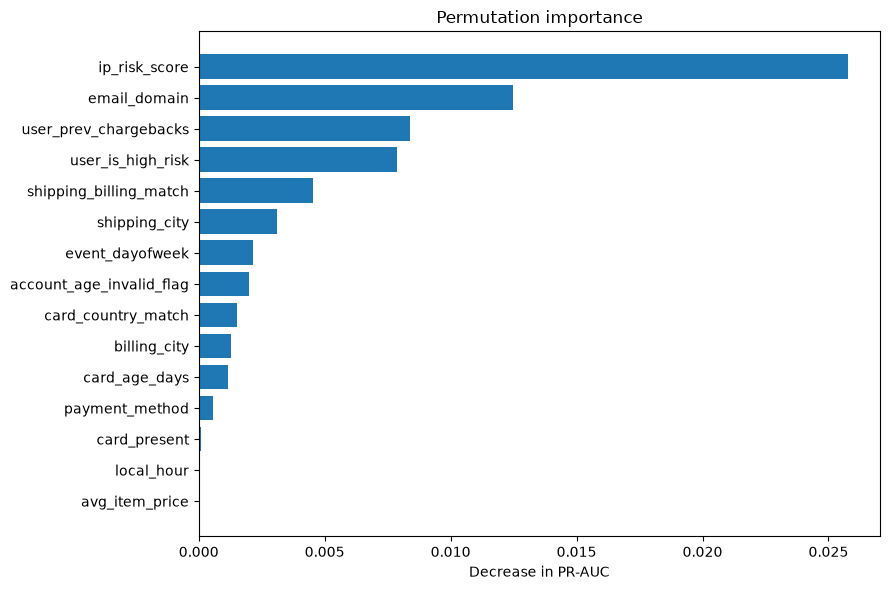

In [28]:
try:
    ix=X_test.sample(min(1200,len(X_test)),random_state=RANDOM_STATE).index
    perm=permutation_importance(best_pipeline,X_test.loc[ix],y_test.loc[ix],scoring="average_precision",
                                n_repeats=3,random_state=RANDOM_STATE,n_jobs=-1)
    importance=pd.DataFrame({"feature":X_test.columns,"importance_mean":perm.importances_mean,
                             "importance_std":perm.importances_std}).sort_values("importance_mean",ascending=False)
    display(importance.head(20))
    top=importance.head(15).sort_values("importance_mean")
    plt.figure(figsize=(9,6));plt.barh(top.feature,top.importance_mean)
    plt.title("Permutation importance");plt.xlabel("Decrease in PR-AUC");plt.tight_layout();plt.show()
except Exception as e:
    importance=pd.DataFrame();print("Importance skipped:",repr(e))

## 19. Save model and reports

In [33]:
import joblib
version=datetime.now(timezone.utc).strftime("uae_fraud_%Y%m%dT%H%M%SZ")
model_path=MODEL_DIR/f"{version}.joblib";joblib.dump(best_pipeline,model_path)
metadata={"model_version":version,"created_utc":datetime.now(timezone.utc).isoformat(),
          "dataset":Path(DATA_PATH).name,"sha256":hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest(),
          "rows":len(df),"fraud_rate":float(df[TARGET].mean()),"model":best_name,
          "threshold":float(selected_threshold),"test_metrics":{k:float(v) for k,v in test_metrics.items()},
          "data_note":"Synthetic proof-of-concept; not production evidence."}
(REPORT_DIR/f"{version}_metadata.json").write_text(json.dumps(metadata,indent=2))
rule_performance.to_csv(REPORT_DIR/"rule_engine_metrics.csv",index=False)
model_comparison.to_csv(REPORT_DIR/"model_comparison.csv",index=False)
monthly.to_csv(REPORT_DIR/"monthly_sales_report.csv")
print("Saved model:",model_path)
print("Reports folder:",REPORT_DIR.resolve())

Saved model: models\uae_fraud_20261106T073611Z.joblib
Reports folder: C:\Users\IQRA TRADERS\Desktop\desktop\5 project AI UAE road MAP\1  ecommerce Middle east\reports


## 20. Executive memo and automated review

In [30]:
memo=f'''
# Executive Summary — UAE E-commerce Fraud Analytics

The retained dataset contains {len(df):,} transactions, including {int(df[TARGET].sum()):,} labeled fraud transactions ({df[TARGET].mean():.2%}). Total transaction value is AED {df.amount_aed.sum():,.2f}; fraud-labeled transaction value is AED {df.fraud_value_aed.sum():,.2f}. These are transaction values, not accounting revenue.

The best validation-PR-AUC model was {best_name}. On the chronological test period it achieved ROC-AUC {test_metrics["ROC_AUC"]:.3f}, PR-AUC {test_metrics["PR_AUC"]:.3f}, precision {test_metrics["precision"]:.2%} and recall {test_metrics["recall"]:.2%}. The threshold was selected on validation data.

Recommendations:
1. Verify velocity, risk and historical-chargeback feature timestamps to rule out leakage.
2. Investigate negative account ages and validate the source-generation process.
3. Confirm manual-review capacity and financial assumptions with Risk and Finance before adopting a policy.
4. Treat this as a proof of concept until real-world validation, security, monitoring and controlled pilot testing are complete.

Limitations: synthetic data; no verified production provenance; NLP cannot be meaningfully trained without genuine text; deep learning is optional; no cloud deployment is performed.
'''
print("Memo word count:",len(memo.split()))
display(Markdown(memo))

Memo word count: 150



# Executive Summary — UAE E-commerce Fraud Analytics

The retained dataset contains 100,000 transactions, including 8,211 labeled fraud transactions (8.21%). Total transaction value is AED 16,286,392.20; fraud-labeled transaction value is AED 1,628,333.28. These are transaction values, not accounting revenue.

The best validation-PR-AUC model was Logistic Regression. On the chronological test period it achieved ROC-AUC 0.700, PR-AUC 0.167, precision 15.24% and recall 53.18%. The threshold was selected on validation data.

Recommendations:
1. Verify velocity, risk and historical-chargeback feature timestamps to rule out leakage.
2. Investigate negative account ages and validate the source-generation process.
3. Confirm manual-review capacity and financial assumptions with Risk and Finance before adopting a policy.
4. Treat this as a proof of concept until real-world validation, security, monitoring and controlled pilot testing are complete.

Limitations: synthetic data; no verified production provenance; NLP cannot be meaningfully trained without genuine text; deep learning is optional; no cloud deployment is performed.


In [38]:
# Final Cost Summary

if "cost_table" in globals():
    display(cost_table)

elif all(
    name in globals()
    for name in ["approve_all_cost", "rule_cost", "ml_cost"]
):
    cost_table = pd.DataFrame({
        "Policy": [
            "Approve All",
            "Existing Fraud Rules",
            "ML Manual Review"
        ],
        "Estimated Cost (AED)": [
            approve_all_cost,
            rule_cost,
            ml_cost
        ]
    })

    display(cost_table.round(2))

else:
    print("Cost analysis has not been calculated.")
    print("Please run the cost-policy calculation cell first.")

Cost analysis has not been calculated.
Please run the cost-policy calculation cell first.


## Final limitations and senior-level conclusion

- Sales reporting is gross transaction value, not accounting revenue or profit.
- Supervised ML uses chronological train/validation/test partitions; target and rule flags are excluded from predictors.
- Isolation Forest and KMeans are exploratory unsupervised methods, not fraud classifiers.
- PyTorch MLP is an optional CPU experiment.
- NLP is only trained when genuine long-form text exists. The current 36-column schema is not expected to contain such a corpus.
- Historical risk, velocity and chargeback features require point-in-time source verification.
- Synthetic data cannot establish real-world fraud performance.
- **Production readiness: NOT READY.** Requires source-data validation, point-in-time feature sign-off, business-cost approval, security review, monitoring, rollback and controlled pilot.

**Run the notebook from top to bottom.** If an optional library is missing, the relevant optional section should skip; core pandas/scikit-learn analysis requires the listed base dependencies.